In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers, models, regularizers

from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.applications.densenet import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.neighbors import NearestNeighbors

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = Path("../data")
IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"
CSV_PATH = DATA_DIR / "GroundTruth.csv"

IMG_SIZE = (320, 320)

DEEPSMOTE_IMG_SIZE = (128, 128)

BATCH_SIZE = 32
EPOCHS = 200
LEARNING_RATE = 0.0001

AE_EPOCHS = 150
AE_BATCH_SIZE = 64
LATENT_DIM = 512
AE_LEARNING_RATE = 0.0002

TEST_SIZE = 0.20
VAL_SIZE = 0.20

USE_DULL_RAZOR = False
USE_MASK_SEGMENTATION = False
USE_MASK_CROP = True
CROP_MARGIN = 20

BEST_MODEL_PATH = "../models/transfer_learning/best_densenet201_crop_deepsmote_320.keras"
FINAL_MODEL_PATH = "../models/transfer_learning/densenet201_crop_deepsmote_320_final.keras"
FEATURE_EXTRACTOR_PATH = "../models/transfer_learning/densenet201_crop_320_feature_extractor.keras"

AUTOENCODER_PATH = "../models/transfer_learning/deepsmote_autoencoder_64.keras"
ENCODER_PATH = "../models/transfer_learning/deepsmote_encoder_64.keras"
DECODER_PATH = "../models/transfer_learning/deepsmote_decoder_64.keras"

classes = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]
class_code = {label: idx for idx, label in enumerate(classes)}
class_name = {idx: label for label, idx in class_code.items()}

print("IMG_SIZE:", IMG_SIZE)
print("DEEPSMOTE_IMG_SIZE:", DEEPSMOTE_IMG_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)
print("EPOCHS:", EPOCHS)
print("AE_EPOCHS:", AE_EPOCHS)
print("LATENT_DIM:", LATENT_DIM)
print("USE_DULL_RAZOR:", USE_DULL_RAZOR)
print("USE_MASK_SEGMENTATION:", USE_MASK_SEGMENTATION)
print("USE_MASK_CROP:", USE_MASK_CROP)
print("CROP_MARGIN:", CROP_MARGIN)

IMG_SIZE: (320, 320)
DEEPSMOTE_IMG_SIZE: (128, 128)
BATCH_SIZE: 32
EPOCHS: 200
AE_EPOCHS: 150
LATENT_DIM: 512
USE_DULL_RAZOR: False
USE_MASK_SEGMENTATION: False
USE_MASK_CROP: True
CROP_MARGIN: 20


In [3]:
def find_image_path(image_id, images_dir):
    for ext in [".jpg", ".jpeg", ".png"]:
        path = images_dir / f"{image_id}{ext}"
        if path.exists():
            return str(path)
    return None


def find_mask_path(image_id, masks_dir):
    if not masks_dir.exists():
        return None

    candidates = [
        masks_dir / f"{image_id}_segmentation.png",
        masks_dir / f"{image_id}_segmentation.jpg",
        masks_dir / f"{image_id}_mask.png",
        masks_dir / f"{image_id}_mask.jpg",
        masks_dir / f"{image_id}.png",
        masks_dir / f"{image_id}.jpg",
    ]

    for path in candidates:
        if path.exists():
            return str(path)

    matches = list(masks_dir.glob(f"{image_id}*"))
    if len(matches) > 0:
        return str(matches[0])

    return None


metadata = pd.read_csv(CSV_PATH)

rows = []

for _, row in metadata.iterrows():
    image_id = str(row["image"])
    image_path = find_image_path(image_id, IMAGES_DIR)
    mask_path = find_mask_path(image_id, MASKS_DIR)

    if image_path is None:
        continue

    label_name = row[classes].idxmax()
    label = class_code[label_name]

    rows.append({
        "image": image_id,
        "image_path": image_path,
        "mask_path": mask_path,
        "class_name": label_name,
        "label": label
    })

df = pd.DataFrame(rows)

print("Total de imagens:", len(df))
print(df["class_name"].value_counts().reindex(classes))

Total de imagens: 10015
class_name
MEL      1113
NV       6705
BCC       514
AKIEC     327
BKL      1099
DF        115
VASC      142
Name: count, dtype: int64


In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=df["label"]
)

print("Treino original:", len(train_df))
print("Teste final:", len(test_df))

print("\nDistribuição treino original:")
print(train_df["class_name"].value_counts().reindex(classes))

print("\nDistribuição teste final:")
print(test_df["class_name"].value_counts().reindex(classes))

Treino original: 8012
Teste final: 2003

Distribuição treino original:
class_name
MEL       890
NV       5364
BCC       411
AKIEC     262
BKL       879
DF         92
VASC      114
Name: count, dtype: int64

Distribuição teste final:
class_name
MEL       223
NV       1341
BCC       103
AKIEC      65
BKL       220
DF         23
VASC       28
Name: count, dtype: int64


In [5]:
def read_rgb_image(path):
    if isinstance(path, bytes):
        path = path.decode("utf-8")

    image_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)

    if image_bgr is None:
        raise ValueError(f"Não foi possível carregar a imagem: {path}")

    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


def dull_razor_remove_hair(image_rgb, kernel_size=(9, 9), threshold_value=10, inpaint_radius=6):
    image_rgb = image_rgb.astype(np.uint8)
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, kernel_size)
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    blackhat_blur = cv2.GaussianBlur(blackhat, (3, 3), 0)

    _, mask = cv2.threshold(
        blackhat_blur,
        threshold_value,
        255,
        cv2.THRESH_BINARY
    )

    image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)

    clean_bgr = cv2.inpaint(
        image_bgr,
        mask,
        inpaint_radius,
        cv2.INPAINT_TELEA
    )

    return cv2.cvtColor(clean_bgr, cv2.COLOR_BGR2RGB)


def read_binary_mask(mask_path, target_shape):
    if mask_path is None or pd.isna(mask_path):
        return None

    if isinstance(mask_path, bytes):
        mask_path = mask_path.decode("utf-8")

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        return None

    height, width = target_shape[:2]
    mask = cv2.resize(mask, (width, height))

    return (mask > 127).astype(np.uint8)


def apply_mask_segmentation(image_rgb, mask_path):
    binary_mask = read_binary_mask(mask_path, target_shape=image_rgb.shape)

    if binary_mask is None:
        return image_rgb

    segmented = image_rgb * np.expand_dims(binary_mask, axis=-1)

    if np.mean(segmented) < 5:
        return image_rgb

    return segmented


def crop_lesion_with_margin(image_rgb, mask_path, margin=20):
    binary_mask = read_binary_mask(mask_path, target_shape=image_rgb.shape)

    if binary_mask is None:
        return image_rgb

    ys, xs = np.where(binary_mask > 0)

    if len(xs) == 0 or len(ys) == 0:
        return image_rgb

    height, width = image_rgb.shape[:2]

    x_min = max(xs.min() - margin, 0)
    x_max = min(xs.max() + margin, width - 1)
    y_min = max(ys.min() - margin, 0)
    y_max = min(ys.max() + margin, height - 1)

    cropped = image_rgb[y_min:y_max + 1, x_min:x_max + 1]

    if cropped.size == 0:
        return image_rgb

    return cropped


def preprocess_base_image(image_path, mask_path=None):
    image = read_rgb_image(image_path)

    if USE_DULL_RAZOR:
        image = dull_razor_remove_hair(image)

    if USE_MASK_CROP:
        image = crop_lesion_with_margin(image, mask_path, margin=CROP_MARGIN)
    elif USE_MASK_SEGMENTATION:
        image = apply_mask_segmentation(image, mask_path)

    return image.astype("float32")


def preprocess_image_path(image_path, mask_path=None, target_size=IMG_SIZE):
    image = preprocess_base_image(image_path, mask_path)
    image = cv2.resize(image, target_size)
    return image.astype("float32")


def preprocess_for_deepsmote(image_path, mask_path=None):
    image = preprocess_base_image(image_path, mask_path)
    image = cv2.resize(image, DEEPSMOTE_IMG_SIZE)
    image = image.astype("float32")
    image = (image / 127.5) - 1.0
    return image

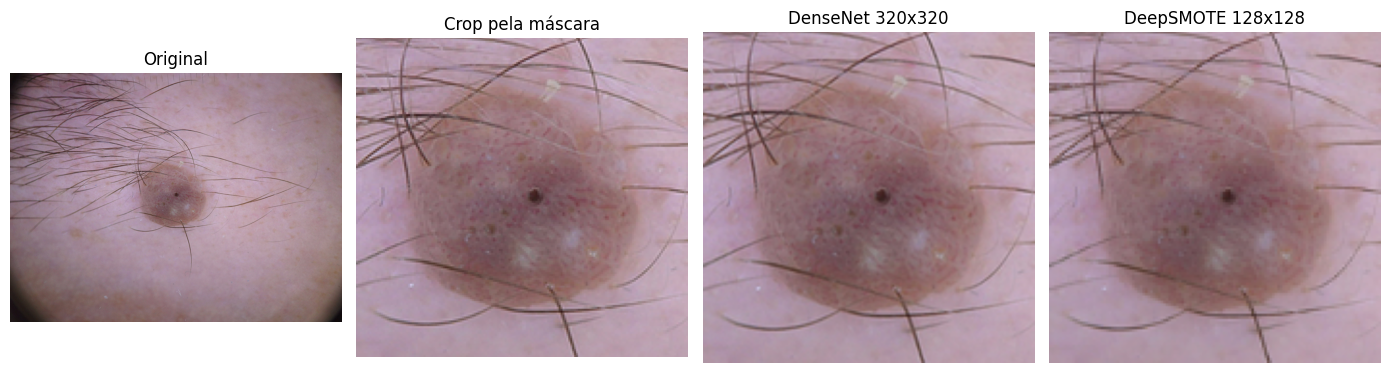

In [6]:
sample_row = train_df.sample(1, random_state=SEED).iloc[0]

original = read_rgb_image(sample_row["image_path"])
cropped = preprocess_base_image(sample_row["image_path"], sample_row["mask_path"])
final_densenet = preprocess_image_path(sample_row["image_path"], sample_row["mask_path"], target_size=IMG_SIZE)
final_deepsmote = preprocess_for_deepsmote(sample_row["image_path"], sample_row["mask_path"])

plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(np.clip(cropped, 0, 255).astype("uint8"))
plt.title("Crop pela máscara")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(np.clip(final_densenet, 0, 255).astype("uint8"))
plt.title("DenseNet 320x320")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(((final_deepsmote + 1.0) * 127.5).astype("uint8"))
plt.title("DeepSMOTE 128x128")
plt.axis("off")

plt.tight_layout()
plt.savefig("preprocessamento_densenet201_deepsmote.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
def load_image_for_features_py(image_path, mask_path, label):
    if isinstance(image_path, bytes):
        image_path = image_path.decode("utf-8")

    if isinstance(mask_path, bytes):
        mask_path = mask_path.decode("utf-8")

    if mask_path == "None" or mask_path == "":
        mask_path = None

    image = preprocess_image_path(image_path, mask_path, target_size=IMG_SIZE)

    return image.astype("float32"), np.int32(label)


def tf_load_image_for_features(image_path, mask_path, label):
    image, label = tf.numpy_function(
        load_image_for_features_py,
        [image_path, mask_path, label],
        [tf.float32, tf.int32]
    )

    image.set_shape((IMG_SIZE[0], IMG_SIZE[1], 3))
    label.set_shape(())

    return image, label


def build_image_dataset(dataframe, batch_size=BATCH_SIZE, shuffle=False):
    mask_values = dataframe["mask_path"].fillna("None").astype(str).values

    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].astype(str).values,
        mask_values,
        dataframe["label"].astype("int32").values
    ))

    ds = ds.map(
        tf_load_image_for_features,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED)

    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_image_ds = build_image_dataset(train_df, shuffle=False)
test_image_ds = build_image_dataset(test_df, shuffle=False)

In [8]:
def dataframe_to_deepsmote_arrays(dataframe):
    X = []
    y = []

    for _, row in dataframe.reset_index(drop=True).iterrows():
        image = preprocess_for_deepsmote(row["image_path"], row["mask_path"])
        X.append(image)
        y.append(int(row["label"]))

    X = np.array(X, dtype="float32")
    y = np.array(y, dtype="int32")

    return X, y


X_train_ae, y_train_ae = dataframe_to_deepsmote_arrays(train_df)

print("X_train_ae:", X_train_ae.shape)
print("y_train_ae:", y_train_ae.shape)
print("Distribuição:", Counter(y_train_ae))

X_train_ae: (8012, 128, 128, 3)
y_train_ae: (8012,)
Distribuição: Counter({np.int32(1): 5364, np.int32(0): 890, np.int32(4): 879, np.int32(2): 411, np.int32(3): 262, np.int32(6): 114, np.int32(5): 92})


In [9]:
def build_deepsmote_autoencoder(input_shape=(64, 64, 3), latent_dim=256):
    encoder_inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(32, 4, strides=2, padding="same")(encoder_inputs)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(64, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(128, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    x = layers.Conv2D(256, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)

    shape_before_flatten = x.shape[1:]
    shape_before_flatten = tuple(int(dim) for dim in shape_before_flatten)

    x = layers.Flatten()(x)
    latent = layers.Dense(latent_dim, name="latent_vector")(x)

    encoder = models.Model(
        encoder_inputs,
        latent,
        name="deepsmote_encoder"
    )

    decoder_inputs = layers.Input(shape=(latent_dim,))

    flatten_units = int(np.prod(shape_before_flatten))

    x = layers.Dense(flatten_units)(decoder_inputs)
    x = layers.Reshape(shape_before_flatten)(x)

    x = layers.Conv2DTranspose(128, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2DTranspose(64, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2DTranspose(32, 4, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    decoder_outputs = layers.Conv2DTranspose(
        3,
        4,
        strides=2,
        padding="same",
        activation="tanh"
    )(x)

    decoder = models.Model(
        decoder_inputs,
        decoder_outputs,
        name="deepsmote_decoder"
    )

    autoencoder_outputs = decoder(encoder(encoder_inputs))

    autoencoder = models.Model(
        encoder_inputs,
        autoencoder_outputs,
        name="deepsmote_autoencoder"
    )

    return autoencoder, encoder, decoder


autoencoder, deepsmote_encoder, deepsmote_decoder = build_deepsmote_autoencoder(
    input_shape=(DEEPSMOTE_IMG_SIZE[0], DEEPSMOTE_IMG_SIZE[1], 3),
    latent_dim=LATENT_DIM
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=AE_LEARNING_RATE),
    loss="mse"
)

autoencoder.summary()

Model: "deepsmote_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deepsmote_encoder (Functional)  │ (None, 512)            │     9,081,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deepsmote_decoder (Functional)  │ (None, 128, 128, 3)    │     9,095,779 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,176,835 (69.34 MB)

 Trainable params: 18,175,491 (69.33 MB)

 Non-trainable params: 1,344 (5.25 KB)

In [10]:
ae_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        AUTOENCODER_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

ae_history = autoencoder.fit(
    X_train_ae,
    X_train_ae,
    validation_split=0.10,
    epochs=AE_EPOCHS,
    batch_size=AE_BATCH_SIZE,
    callbacks=ae_callbacks,
    shuffle=True
)

Epoch 1/150
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - loss: 0.1586
Epoch 1: val_loss improved from None to 0.10521, saving model to ../models/transfer_learning/deepsmote_autoencoder_64.keras

Epoch 1: finished saving model to ../models/transfer_learning/deepsmote_autoencoder_64.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 36s 297ms/step - loss: 0.0962 - val_loss: 0.1052 - learning_rate: 2.0000e-04
Epoch 2/150
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - loss: 0.0266
Epoch 2: val_loss improved from 0.10521 to 0.07436, saving model to ../models/transfer_learning/deepsmote_autoencoder_64.keras

Epoch 2: finished saving model to ../models/transfer_learning/deepsmote_autoencoder_64.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 35s 307ms/step - loss: 0.0222 - val_loss: 0.0744 - learning_rate: 2.0000e-04
Epoch 3/150
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - loss: 0.0157
Epoch 3: val_loss improved from 0.07436 to 0.04194, saving model to ../models/transfer_learning/deepsmote_autoencoder_64.keras

Epoch 3: fi

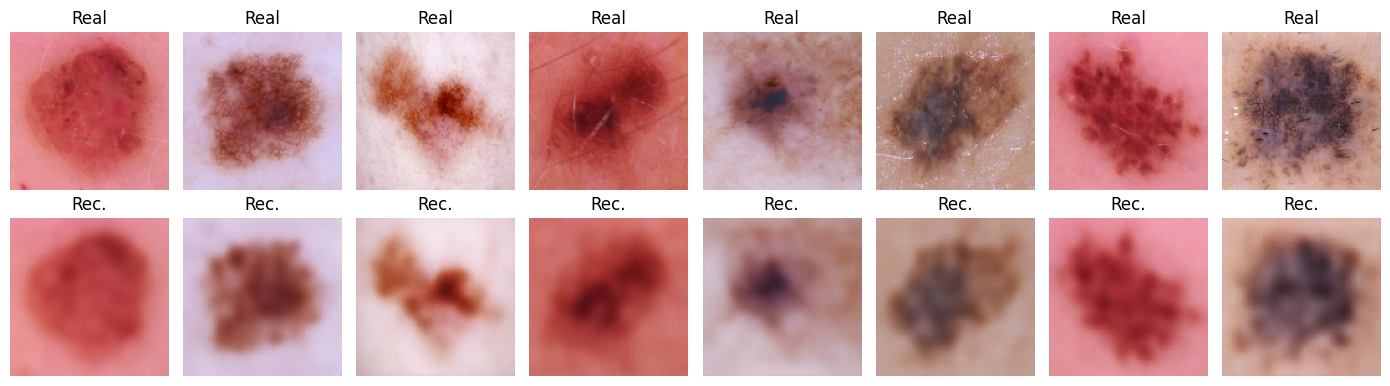

In [11]:
best_autoencoder = keras.models.load_model(AUTOENCODER_PATH)

sample_images = X_train_ae[:8]
recon_images = best_autoencoder.predict(sample_images, verbose=0)

plt.figure(figsize=(14, 4))

for i in range(8):
    plt.subplot(2, 8, i + 1)
    img = ((sample_images[i] + 1.0) * 127.5)
    plt.imshow(np.clip(img, 0, 255).astype("uint8"))
    plt.title("Real")
    plt.axis("off")

    plt.subplot(2, 8, i + 9)
    rec = ((recon_images[i] + 1.0) * 127.5)
    plt.imshow(np.clip(rec, 0, 255).astype("uint8"))
    plt.title("Rec.")
    plt.axis("off")

plt.tight_layout()
plt.savefig("reconstrucoes_deepsmote_autoencoder.png", dpi=300, bbox_inches="tight")
plt.show()

deepsmote_encoder = best_autoencoder.get_layer("deepsmote_encoder")
deepsmote_decoder = best_autoencoder.get_layer("deepsmote_decoder")

Classe selecionada: MEL
Quantidade de imagens reais disponíveis: 890


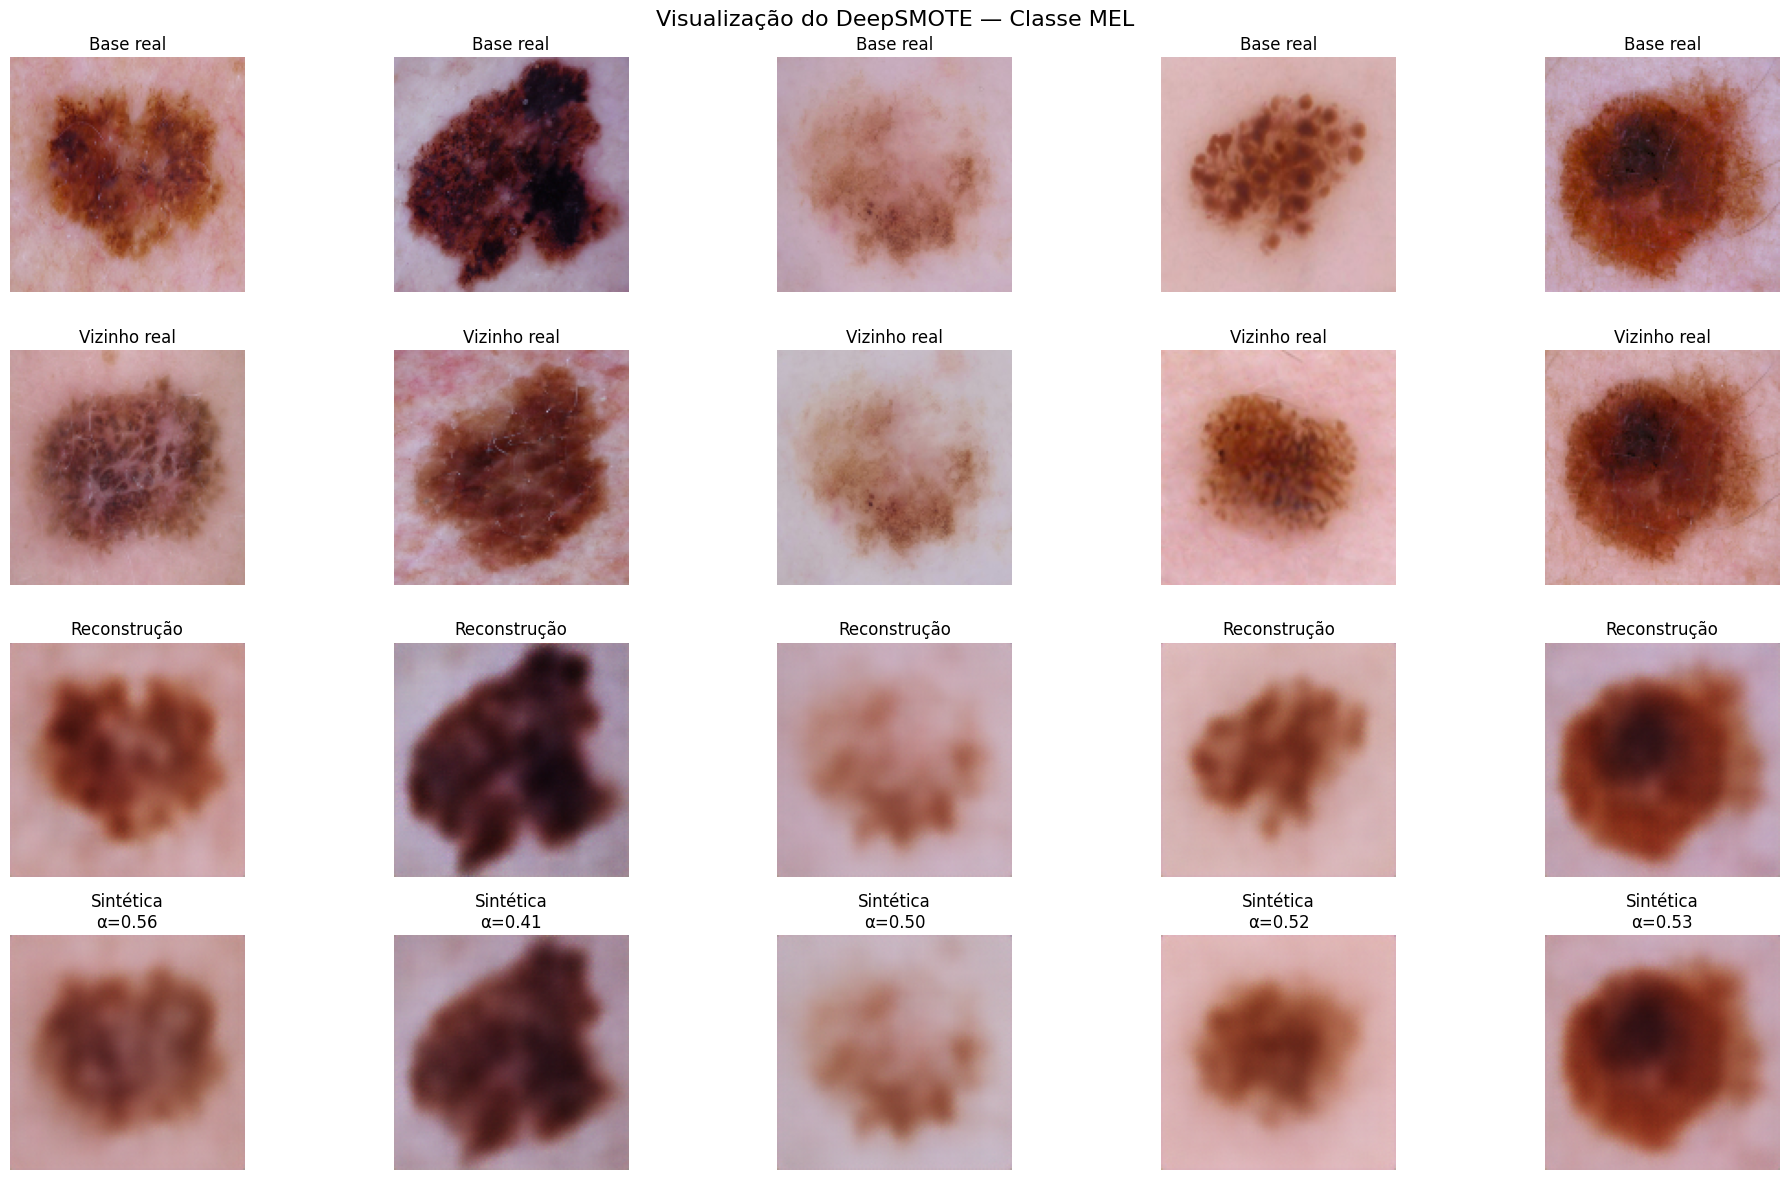

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# Classe que você quer visualizar
VIS_CLASS_NAME = "MEL"   # troque para "NV", "BCC", "AKIEC", "BKL", "DF" ou "VASC"
N_EXAMPLES = 5
K_NEIGHBORS_VIS = 5

vis_class_id = class_code[VIS_CLASS_NAME]

# Filtra imagens reais da classe escolhida
X_class = X_train_ae[y_train_ae == vis_class_id]
y_class = y_train_ae[y_train_ae == vis_class_id]

print("Classe selecionada:", VIS_CLASS_NAME)
print("Quantidade de imagens reais disponíveis:", len(X_class))

if len(X_class) < 2:
    raise ValueError("É necessário pelo menos 2 imagens da classe para gerar exemplos DeepSMOTE.")

# Seleciona poucas imagens reais
n_show = min(N_EXAMPLES, len(X_class))
sample_indices = np.random.choice(len(X_class), size=n_show, replace=False)

X_real = X_class[sample_indices]

# Codifica todas as imagens da classe para encontrar vizinhos
Z_class = deepsmote_encoder.predict(X_class, verbose=0)
Z_real = Z_class[sample_indices]

# Reconstrói as imagens reais selecionadas
X_recon = deepsmote_decoder.predict(Z_real, verbose=0)

# Busca vizinhos no espaço latente
Z_class_flat = Z_class.reshape(len(Z_class), -1)
Z_real_flat = Z_real.reshape(len(Z_real), -1)

n_neighbors = min(K_NEIGHBORS_VIS + 1, len(Z_class_flat))

nn_model = NearestNeighbors(n_neighbors=n_neighbors)
nn_model.fit(Z_class_flat)

distances, indices = nn_model.kneighbors(Z_real_flat)

# Gera imagens sintéticas
X_neighbors = []
X_synth = []
alphas = []

for i in range(n_show):
    # escolhe um vizinho diferente da própria imagem
    neighbor_position = np.random.randint(1, n_neighbors)
    neighbor_idx = indices[i, neighbor_position]

    z_base = Z_real_flat[i]
    z_neighbor = Z_class_flat[neighbor_idx]

    alpha = np.random.uniform(0.2, 0.8)

    z_synth = z_base + alpha * (z_neighbor - z_base)
    z_synth = z_synth.reshape((1,) + Z_real.shape[1:])

    x_synth = deepsmote_decoder.predict(z_synth, verbose=0)[0]

    X_neighbors.append(X_class[neighbor_idx])
    X_synth.append(x_synth)
    alphas.append(alpha)

X_neighbors = np.array(X_neighbors)
X_synth = np.array(X_synth)


def show_img(img):
    img = np.array(img).astype("float32")

    # Caso esteja em [-1, 1]
    if img.min() < 0:
        img = (img + 1.0) / 2.0

    # Caso esteja em [0, 255]
    if img.max() > 1.5:
        img = img / 255.0

    return np.clip(img, 0, 1)


# Visualização
fig, axes = plt.subplots(4, n_show, figsize=(4 * n_show, 12))

for col in range(n_show):
    axes[0, col].imshow(show_img(X_real[col]))
    axes[0, col].set_title("Base real")
    axes[0, col].axis("off")

    axes[1, col].imshow(show_img(X_neighbors[col]))
    axes[1, col].set_title("Vizinho real")
    axes[1, col].axis("off")

    axes[2, col].imshow(show_img(X_recon[col]))
    axes[2, col].set_title("Reconstrução")
    axes[2, col].axis("off")

    axes[3, col].imshow(show_img(X_synth[col]))
    axes[3, col].set_title(f"Sintética\nα={alphas[col]:.2f}")
    axes[3, col].axis("off")

plt.suptitle(f"Visualização do DeepSMOTE — Classe {VIS_CLASS_NAME}", fontsize=16)
plt.tight_layout()
plt.savefig(f"visualizacao_deepsmote_{VIS_CLASS_NAME}.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
def generate_latent_samples_for_class(latent_vectors, n_to_sample, class_label, n_neighbors=6):
    if n_to_sample <= 0:
        return np.empty((0, latent_vectors.shape[1]), dtype="float32"), np.empty((0,), dtype="int32")

    if len(latent_vectors) < 2:
        sampled = np.repeat(latent_vectors, repeats=n_to_sample, axis=0)
        labels = np.array([class_label] * n_to_sample, dtype="int32")
        return sampled.astype("float32"), labels

    n_neighbors = min(n_neighbors, len(latent_vectors))

    nn = NearestNeighbors(n_neighbors=n_neighbors, n_jobs=-1)
    nn.fit(latent_vectors)

    _, indices = nn.kneighbors(latent_vectors)

    base_indices = np.random.choice(np.arange(len(latent_vectors)), size=n_to_sample, replace=True)
    neighbor_choices = np.random.choice(np.arange(1, n_neighbors), size=n_to_sample, replace=True)

    z_base = latent_vectors[base_indices]
    z_neighbor = latent_vectors[indices[base_indices, neighbor_choices]]

    alpha = np.random.rand(n_to_sample, 1).astype("float32")
    z_synthetic = z_base + alpha * (z_neighbor - z_base)

    labels = np.array([class_label] * n_to_sample, dtype="int32")

    return z_synthetic.astype("float32"), labels


def decode_latent_in_batches(decoder, latent_samples, batch_size=AE_BATCH_SIZE):
    decoded = decoder.predict(latent_samples, batch_size=batch_size, verbose=0)
    decoded = np.clip(decoded, -1.0, 1.0)
    return decoded.astype("float32")


def deepsmote_balance_images(X_images, y_labels, encoder, decoder):
    counter = Counter(y_labels)
    target_count = max(counter.values())

    print("Distribuição antes do DeepSMOTE:")
    print(counter)
    print("Classe alvo:", target_count)

    latent_all = encoder.predict(X_images, batch_size=AE_BATCH_SIZE, verbose=0)

    synthetic_images = []
    synthetic_labels = []

    for class_id in sorted(counter.keys()):
        class_count = counter[class_id]
        n_to_sample = target_count - class_count

        print(f"Classe {class_name[int(class_id)]}: atual={class_count}, gerar={n_to_sample}")

        if n_to_sample <= 0:
            continue

        class_latents = latent_all[y_labels == class_id]

        z_synth, y_synth = generate_latent_samples_for_class(
            class_latents,
            n_to_sample=n_to_sample,
            class_label=class_id,
            n_neighbors=6
        )

        x_synth = decode_latent_in_batches(decoder, z_synth)

        synthetic_images.append(x_synth)
        synthetic_labels.append(y_synth)

    if len(synthetic_images) == 0:
        return X_images, y_labels, np.empty((0,) + X_images.shape[1:], dtype="float32"), np.empty((0,), dtype="int32")

    X_synth = np.concatenate(synthetic_images, axis=0)
    y_synth = np.concatenate(synthetic_labels, axis=0)

    X_balanced = np.concatenate([X_images, X_synth], axis=0)
    y_balanced = np.concatenate([y_labels, y_synth], axis=0)

    print("\nSintéticas geradas:", X_synth.shape)
    print("Distribuição após DeepSMOTE:")
    print(Counter(y_balanced))

    return X_balanced.astype("float32"), y_balanced.astype("int32"), X_synth.astype("float32"), y_synth.astype("int32")

In [14]:
X_train_deepsmote_img, y_train_deepsmote, X_synth_img, y_synth = deepsmote_balance_images(
    X_train_ae,
    y_train_ae,
    deepsmote_encoder,
    deepsmote_decoder
)

print("X_train_deepsmote_img:", X_train_deepsmote_img.shape)
print("y_train_deepsmote:", y_train_deepsmote.shape)
print("X_synth_img:", X_synth_img.shape)
print("y_synth:", y_synth.shape)

Distribuição antes do DeepSMOTE:
Counter({np.int32(1): 5364, np.int32(0): 890, np.int32(4): 879, np.int32(2): 411, np.int32(3): 262, np.int32(6): 114, np.int32(5): 92})
Classe alvo: 5364
Classe MEL: atual=890, gerar=4474
Classe NV: atual=5364, gerar=0
Classe BCC: atual=411, gerar=4953
Classe AKIEC: atual=262, gerar=5102
Classe BKL: atual=879, gerar=4485
Classe DF: atual=92, gerar=5272
Classe VASC: atual=114, gerar=5250

Sintéticas geradas: (29536, 128, 128, 3)
Distribuição após DeepSMOTE:
Counter({np.int32(1): 5364, np.int32(0): 5364, np.int32(4): 5364, np.int32(2): 5364, np.int32(5): 5364, np.int32(3): 5364, np.int32(6): 5364})
X_train_deepsmote_img: (37548, 128, 128, 3)
y_train_deepsmote: (37548,)
X_synth_img: (29536, 128, 128, 3)
y_synth: (29536,)


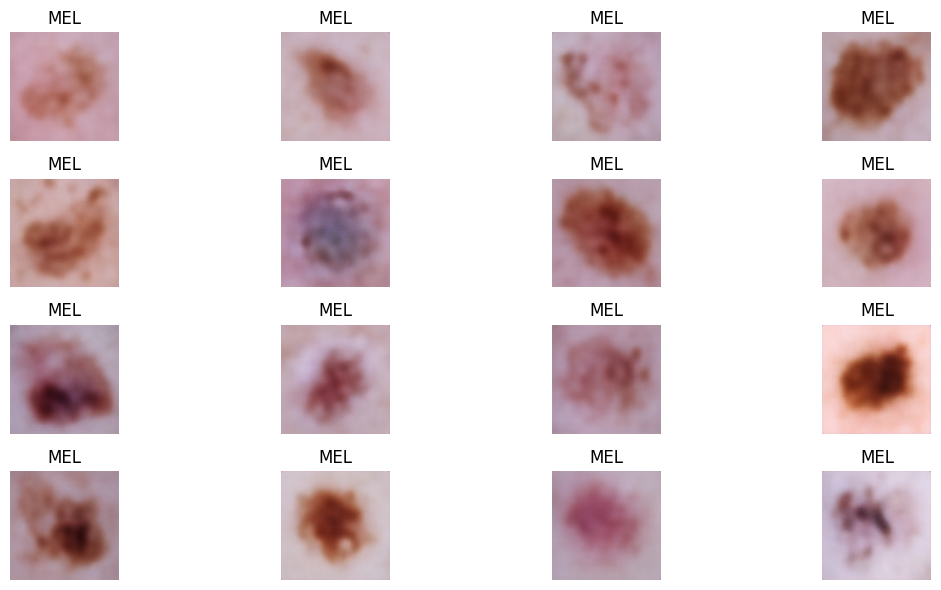

In [15]:
n_show = min(16, len(X_synth_img))

plt.figure(figsize=(12, 6))

for i in range(n_show):
    img = ((X_synth_img[i] + 1.0) * 127.5)
    label = class_name[int(y_synth[i])]

    plt.subplot(4, 4, i + 1)
    plt.imshow(np.clip(img, 0, 255).astype("uint8"))
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.savefig("amostras_sinteticas_deepsmote.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
def build_feature_extractor(input_shape=(320, 320, 3)):
    inputs = layers.Input(shape=input_shape)

    x = preprocess_input(inputs)

    base_model = DenseNet201(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    base_model.trainable = False

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)

    feature_extractor = models.Model(
        inputs=inputs,
        outputs=x,
        name="densenet201_crop_feature_extractor"
    )

    return feature_extractor


feature_extractor = build_feature_extractor(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

feature_extractor.summary()

Model: "densenet201_crop_feature_extractor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 10, 10, 1920)   │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,321,984 (69.89 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 18,321,984 (69.89 MB)

In [ ]:
def extract_features(dataset, feature_extractor):
    features_list = []
    labels_list = []

    for images, labels in dataset:
        features = feature_extractor.predict(images, verbose=0)
        features_list.append(features)
        labels_list.append(labels.numpy())

    X = np.concatenate(features_list, axis=0)
    y = np.concatenate(labels_list, axis=0)

    return X.astype("float32"), y.astype("int32")


X_test_features, y_test = extract_features(test_image_ds, feature_extractor)

print("X_test_features:", X_test_features.shape)
print("y_test:", y_test.shape)
print("Distribuição teste:")
print(Counter(y_test))

X_test_features: (2003, 1920)
y_test: (2003,)
Distribuição teste:
Counter({np.int32(1): 1341, np.int32(0): 223, np.int32(4): 220, np.int32(2): 103, np.int32(3): 65, np.int32(6): 28, np.int32(5): 23})


: 

In [ ]:
def deepsmote_images_to_densenet_input(X_images):
    converted = []

    for img in X_images:
        img_uint = ((img + 1.0) * 127.5)
        img_uint = np.clip(img_uint, 0, 255).astype("float32")
        img_resized = cv2.resize(img_uint, IMG_SIZE)
        converted.append(img_resized)

    return np.array(converted, dtype="float32")


X_train_deepsmote_dense = deepsmote_images_to_densenet_input(X_train_deepsmote_img)

print("X_train_deepsmote_dense:", X_train_deepsmote_dense.shape)

X_train_features_deepsmote = feature_extractor.predict(
    X_train_deepsmote_dense,
    batch_size=BATCH_SIZE,
    verbose=1
)

X_train_features_deepsmote = X_train_features_deepsmote.astype("float32")

print("X_train_features_deepsmote:", X_train_features_deepsmote.shape)
print("y_train_deepsmote:", y_train_deepsmote.shape)
print("Distribuição treino final:")
print(Counter(y_train_deepsmote))

In [ ]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_features_deepsmote,
    y_train_deepsmote,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=y_train_deepsmote
)

print("Treino para fit:", X_fit.shape)
print("Validação:", X_val.shape)
print("Teste final:", X_test_features.shape)

print("\nDistribuição fit:")
print(Counter(y_fit))

print("\nDistribuição validação:")
print(Counter(y_val))

In [ ]:
def build_classifier_head(input_dim, num_classes=len(classes)):
    inputs = layers.Input(shape=(input_dim,))

    x = layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)

    x = layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    )(x)

    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="densenet201_crop_deepsmote_classifier"
    )

    return model


classifier = build_classifier_head(
    input_dim=X_train_features_deepsmote.shape[1],
    num_classes=len(classes)
)

classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

classifier.summary()

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=4,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = classifier.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks
)

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Treino")
plt.plot(history.history["val_accuracy"], label="Validação")
plt.title("Acurácia durante o treinamento")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("acuracia_densenet201_crop_deepsmote.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Treino")
plt.plot(history.history["val_loss"], label="Validação")
plt.title("Perda durante o treinamento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("loss_densenet201_crop_deepsmote.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
best_classifier = keras.models.load_model(BEST_MODEL_PATH)

pred_probs = best_classifier.predict(X_test_features, verbose=0)
y_pred = np.argmax(pred_probs, axis=1)

print("Relatório de Classificação:")
print(classification_report(
    y_test,
    y_pred,
    target_names=classes,
    digits=4,
    zero_division=0
))

acc = accuracy_score(y_test, y_pred)

macro_precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
macro_recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

weighted_precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
weighted_recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("\nMÉTRICAS GERAIS DO MODELO")
print(f"Accuracy: {acc:.4f}")

print("\nMacro Average:")
print(f"  Precision: {macro_precision:.4f}")
print(f"  Recall: {macro_recall:.4f}")
print(f"  F1-Score: {macro_f1:.4f}")

print("\nWeighted Average:")
print(f"  Precision: {weighted_precision:.4f}")
print(f"  Recall: {weighted_recall:.4f}")
print(f"  F1-Score: {weighted_f1:.4f}")

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(len(classes))))
cm_percent = cm.astype("float") / cm.sum(axis=1, keepdims=True) * 100
cm_percent = np.nan_to_num(cm_percent)

plt.figure(figsize=(8, 7))
im = plt.imshow(cm_percent, interpolation="nearest", cmap="Blues", vmin=0, vmax=100)
plt.title("Matriz de Confusão (%) - DenseNet201 + Crop + DeepSMOTE + 320x320")
plt.colorbar(im, label="%")

tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

for i in range(cm_percent.shape[0]):
    for j in range(cm_percent.shape[1]):
        color = "white" if cm_percent[i, j] > 50 else "black"
        plt.text(
            j,
            i,
            f"{cm_percent[i, j]:.1f}",
            ha="center",
            va="center",
            color=color,
            fontsize=8
        )

plt.ylabel("Classe Real")
plt.xlabel("Classe Predita")
plt.tight_layout()
plt.savefig("matriz_confusao_percent_densenet201_crop_deepsmote.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
test_eval_df = test_df.copy().reset_index(drop=True)
test_eval_df["y_true"] = y_test
test_eval_df["y_pred"] = y_pred
test_eval_df["correct"] = test_eval_df["y_true"] == test_eval_df["y_pred"]

correct_samples = test_eval_df[test_eval_df["correct"]].head(4)
incorrect_samples = test_eval_df[~test_eval_df["correct"]].head(4)

samples_to_plot = pd.concat([correct_samples, incorrect_samples], axis=0).reset_index(drop=True)

plt.figure(figsize=(12, 6))

for i, row in samples_to_plot.iterrows():
    image = preprocess_image_path(row["image_path"], row["mask_path"], target_size=IMG_SIZE)
    image = np.clip(image, 0, 255).astype("uint8")

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)

    true_label = class_name[int(row["y_true"])]
    pred_label = class_name[int(row["y_pred"])]

    plt.title(f"{true_label} → {pred_label}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.savefig("exemplos_classificacao_densenet201_crop_deepsmote.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
feature_extractor.save(FEATURE_EXTRACTOR_PATH)
best_classifier.save(FINAL_MODEL_PATH)

deepsmote_encoder.save(ENCODER_PATH)
deepsmote_decoder.save(DECODER_PATH)

print("Extratora DenseNet201 salva em:", FEATURE_EXTRACTOR_PATH)
print("Classificador final salvo em:", FINAL_MODEL_PATH)
print("Melhor checkpoint salvo em:", BEST_MODEL_PATH)
print("Encoder DeepSMOTE salvo em:", ENCODER_PATH)
print("Decoder DeepSMOTE salvo em:", DECODER_PATH)